# **#  Group 4 Exploratory Data Analysis (IB)**

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [79]:
international_baccalaureate = pd.read_csv('International Baccalaureate.csv')
copy = international_baccalaureate

/tmp/ipykernel_2076/3407628051.py:1: DtypeWarning: Columns (2,6) have mixed types. Specify dtype option on import or set low_memory=False.
  international_baccalaureate = pd.read_csv('International Baccalaureate.csv')


In [80]:
#filter out non high schools
hs_has_ib = international_baccalaureate.loc[(international_baccalaureate['TOT_IBENR_M'] > 0) & (international_baccalaureate['TOT_IBENR_F'] > 0)]
hs_has_ib.sample(3)

,LEA_STATE,LEA_STATE_NAME,LEAID,LEA_NAME,SCHID,SCH_NAME,COMBOKEY,SCH_JUST,SCH_IBENR_IND,SCH_IBENR_HI_M,...,TOT_IBENR_X,SCH_IBENR_EL_M,SCH_IBENR_EL_F,SCH_IBENR_EL_X,SCH_IBENR_IDEA_M,SCH_IBENR_IDEA_F,SCH_IBENR_IDEA_X,SCH_IBENR_504_M,SCH_IBENR_504_F,SCH_IBENR_504_X
50134,MT,MONTANA,3000654,Big Sky School K-12,1099,LONE PEAK HIGH SCHOOL,300065401099,No,Yes,1,...,-10,0,0,-10,0,0,-10,1,0,-10
70446,OR,OREGON,4104740,Eugene SD 4J,571,NORTH EUGENE HIGH SCHOOL,410474000571,No,Yes,42,...,-10,9,9,-10,15,19,-10,19,34,-10
41268,MI,MICHIGAN,2600232,Detroit Edison Public School Academy,8742,DETROIT EDISON PUBLIC SCHOOL ACADEMY - HIGH SC...,260023208742,No,Yes,2,...,-10,4,9,-10,11,11,-10,1,2,-10


In [81]:
# make negatives NaN
hs_has_ib = hs_has_ib.replace(-10, np.nan)
hs_has_ib = hs_has_ib.replace(-9, np.nan)
# drop columns with only NaN
hs_has_ib = hs_has_ib.dropna(axis=1, how="all")
# drop repetative columns
hs_has_ib = hs_has_ib.drop(columns=['LEA_STATE_NAME','LEAID','SCHID'])
# make school and district names titlecase
hs_has_ib['LEA_NAME'] = hs_has_ib['LEA_NAME'].str.title()
hs_has_ib['SCH_NAME'] = hs_has_ib['SCH_NAME'].str.title()
hs_has_ib.sample(3)

,LEA_STATE,LEA_NAME,SCH_NAME,COMBOKEY,SCH_JUST,SCH_IBENR_IND,SCH_IBENR_HI_M,SCH_IBENR_HI_F,SCH_IBENR_AM_M,SCH_IBENR_AM_F,...,SCH_IBENR_TR_M,SCH_IBENR_TR_F,TOT_IBENR_M,TOT_IBENR_F,SCH_IBENR_EL_M,SCH_IBENR_EL_F,SCH_IBENR_IDEA_M,SCH_IBENR_IDEA_F,SCH_IBENR_504_M,SCH_IBENR_504_F
34897,KY,Covington Independent,Holmes High School,210135002049,No,Yes,3,3,0,0,...,0,2,10,19,1,1,0,0,0,0
75564,SC,York 03,Northwestern High,450387001149,No,Yes,0,0,0,0,...,0,0,4,8,0,0,0,0,0,1
17774,CT,Regional School District 04,Valley Regional High School,90363000768,No,Yes,16,11,0,0,...,6,4,104,118,3,1,3,3,23,21


In [82]:
# clean and make readable existing columns
column_names = [x.replace('SCH_', '') for x in hs_has_ib.columns]
column_names = [x.replace('IBENR_', '') for x in column_names]
column_names = [x.replace('TOT_', 'Total') for x in column_names]
hs_has_ib.columns = column_names

hs_has_ib = hs_has_ib.rename(columns={"LEA_STATE": "State"})
hs_has_ib = hs_has_ib.rename(columns={"LEA_NAME": "District"})
hs_has_ib = hs_has_ib.rename(columns={"NAME": "School"})
hs_has_ib = hs_has_ib.rename(columns={"COMBOKEY": "Combo-key"})
hs_has_ib = hs_has_ib.rename(columns={"JUST": "Justice Facility"})
hs_has_ib = hs_has_ib.rename(columns={"HI_M": "Hispanic Male","HI_F": "Hispanic Female"})
hs_has_ib = hs_has_ib.rename(columns={"AM_M": "Native American Male","AM_F": "Native American Female"})
hs_has_ib = hs_has_ib.rename(columns={"AS_M": "Asian Male","AS_F": "Asian Female"})
hs_has_ib = hs_has_ib.rename(columns={"HP_M": "Pacific Islander Male","HP_F": "Pacific Islander Female"})
hs_has_ib = hs_has_ib.rename(columns={"BL_M": "Black Male", "BL_F": "Black Female"})
hs_has_ib = hs_has_ib.rename(columns={"WH_M": "White Male", "WH_F": "White Female"})
hs_has_ib = hs_has_ib.rename(columns={"TR_M": "Two or more races Male", "TR_F": "Two or more races Female"})
hs_has_ib = hs_has_ib.rename(columns={"EL_M": "EL Male", "EL_F": "EL Female"})
hs_has_ib = hs_has_ib.rename(columns={"IDEA_M": "IDEA Male", "IDEA_F": "IDEA Female"})
hs_has_ib = hs_has_ib.rename(columns={"Total_M": "Total Male", "Total_F": "Total Female"})

In [83]:
hs_has_ib.sample(3)

,State,District,School,Combo-key,Justice Facility,IND,Hispanic Male,Hispanic Female,Native American Male,Native American Female,...,Two or more races Male,Two or more races Female,TotalM,TotalF,EL Male,EL Female,IDEA Male,IDEA Female,504_M,504_F
71379,PA,Lehigh Valley Academy Regional Cs,Lehigh Valley Academy Regional Cs,420009800635,No,Yes,28,42,0,0,...,6,13,68,87,12,11,11,12,1,9
7891,CA,Conejo Valley Unified,Newbury Park High,60964001020,No,Yes,20,40,1,2,...,12,19,198,256,3,1,2,3,8,16
21411,FL,Palm Beach,Atlantic High School,120150001527,No,Yes,21,24,1,1,...,3,9,94,151,0,0,1,5,5,13


In [84]:
hs_has_ib['Total'] = hs_has_ib['TotalM'] + hs_has_ib['TotalF']
hs_has_ib['Total White'] = hs_has_ib['White Male'] + hs_has_ib['White Female']
hs_has_ib['Total Nonwhite'] = hs_has_ib['Total'] - hs_has_ib['Total White']
hs_has_ib['Total EL'] = hs_has_ib['EL Male'] + hs_has_ib['EL Female']
hs_has_ib['Total IDEA'] = hs_has_ib['IDEA Male'] + hs_has_ib['IDEA Female']



---



# 1. California

In [85]:
# clean dataframe to be CA schools
ib_ca = hs_has_ib.loc[(hs_has_ib['State']=='CA')]

# descriptive summary of statistics for california data
ib_ca.describe()

,Hispanic Male,Hispanic Female,Native American Male,Native American Female,Asian Male,Asian Female,Pacific Islander Male,Pacific Islander Female,Black Male,Black Female,...,EL Female,IDEA Male,IDEA Female,504_M,504_F,Total,Total White,Total Nonwhite,Total EL,Total IDEA
count,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,...,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000
mean,54.913462,73.365385,0.307692,0.596154,22.673077,23.019231,0.461538,0.711538,3.442308,4.826923,...,7.182692,6.201923,3.836538,4.509615,6.721154,269.028846,70.567308,198.461538,14.663462,10.038462
std,88.822296,90.277572,0.903896,1.610157,35.899926,31.072724,1.230069,1.251586,9.866907,9.371971,...,17.686463,20.170333,10.218117,6.795194,9.809305,257.259736,86.562258,220.698667,40.779685,30.254238
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,0.000000,3.000000,0.000000,0.000000
25%,11.750000,20.750000,0.000000,0.000000,3.000000,4.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,0.750000,0.000000,0.000000,1.000000,104.750000,6.750000,65.000000,1.000000,1.000000
50%,33.500000,56.000000,0.000000,0.000000,9.000000,10.500000,0.000000,0.000000,1.000000,2.000000,...,1.500000,2.000000,2.000000,3.000000,4.500000,209.000000,39.000000,149.500000,3.000000,4.000000
75%,62.250000,95.500000,0.000000,1.000000,28.250000,33.250000,0.000000,1.000000,3.000000,5.000000,...,5.250000,6.000000,3.000000,6.000000,9.250000,371.500000,117.500000,264.250000,8.250000,9.000000
max,798.000000,703.000000,8.000000,11.000000,239.000000,177.000000,8.000000,6.000000,90.000000,75.000000,...,142.000000,199.000000,98.000000,56.000000,81.000000,2001.000000,416.000000,1830.000000,315.000000,297.000000


Text(0.5, 1.0, 'Proportion of non-white students taking IB classes by School in CA')

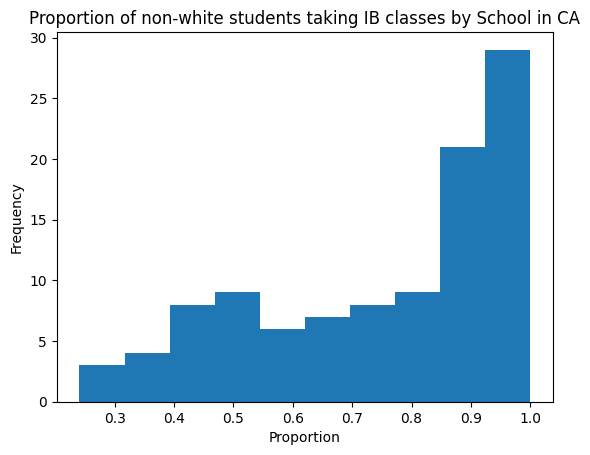

In [86]:
wh_ca = ib_ca['White Male'] + ib_ca['White Female']
total_ca = ib_ca['TotalM'] + ib_ca['TotalF']
non_wh_ca = total_ca - wh_ca
ca_non_wh_prop = non_wh_ca/total_ca
plt.hist(ca_non_wh_prop)
plt.xlabel('Proportion')
plt.ylabel('Frequency')
plt.title('Proportion of non-white students taking IB classes by School in CA')

**Alt-Text:** This is a  histogram showing the proportions of Non-white students per school in IB classes in California, with an X-axis of the proportion values, y-axis of frequency. It is right skewed.

Text(0.5, 1.0, 'Proportion of english-learner students taking IB classes by School in CA')

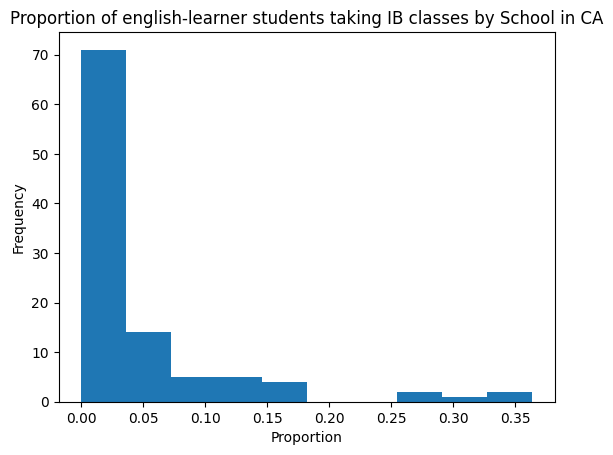

In [87]:
el_ca = ib_ca['EL Male'] + ib_ca['EL Female']
ca_el_prop = el_ca/total_ca
plt.hist(ca_el_prop)
plt.xlabel('Proportion')
plt.ylabel('Frequency')
plt.title('Proportion of english-learner students taking IB classes by School in CA')

**Alt-Text:** This is a  histogram showing the proportions of English learner students per school in IB classes in California, with an X-axis of the proportion values, y-axis of frequency. It is left skewed.

Text(0.5, 1.0, 'Proportion of IDEA students taking IB classes by School in CA')

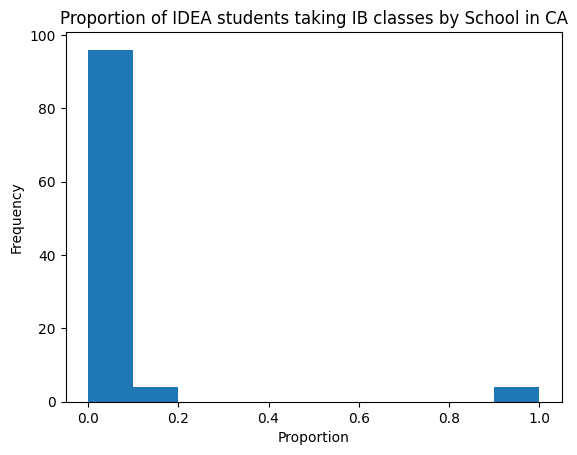

In [88]:
idea_ca = ib_ca['IDEA Male'] + ib_ca['IDEA Female']
ca_idea_prop = idea_ca/total_ca
plt.hist(ca_idea_prop)
plt.xlabel('Proportion')
plt.ylabel('Frequency')
plt.title('Proportion of IDEA students taking IB classes by School in CA')

**Alt-Text:** This is a  histogram showing the proportions of IDEA students per school in IB classes in California, with an X-axis of the proportion values, y-axis of frequency. It is left skewed.



---



# New Mexico

In [89]:
# clean dataframe to be NM schools
ib_nm = hs_has_ib.loc[(hs_has_ib['State']=='NM')]

# descriptive summary of statistics for New Mexico data
ib_nm.describe()


,Hispanic Male,Hispanic Female,Native American Male,Native American Female,Asian Male,Asian Female,Pacific Islander Male,Pacific Islander Female,Black Male,Black Female,...,EL Female,IDEA Male,IDEA Female,504_M,504_F,Total,Total White,Total Nonwhite,Total EL,Total IDEA
count,3.000000,3.000000,3.0,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,...,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
mean,25.666667,37.333333,1.0,1.666667,4.666667,2.666667,0.333333,0.333333,1.333333,2.333333,...,2.333333,5.000000,4.000000,2.000000,3.333333,130.333333,49.333333,81.000000,5.333333,9.000000
std,16.502525,13.428825,1.0,0.577350,2.516611,2.516611,0.577350,0.577350,1.527525,0.577350,...,2.516611,5.291503,5.291503,1.732051,4.041452,59.163615,30.005555,32.357379,5.033223,10.583005
min,9.000000,22.000000,0.0,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,2.000000,...,0.000000,1.000000,0.000000,1.000000,1.000000,63.000000,19.000000,44.000000,0.000000,1.000000
25%,17.500000,32.500000,0.5,1.500000,3.500000,1.500000,0.000000,0.000000,0.500000,2.000000,...,1.000000,2.000000,1.000000,1.000000,1.000000,108.500000,34.500000,69.500000,3.000000,3.000000
50%,26.000000,43.000000,1.0,2.000000,5.000000,3.000000,0.000000,0.000000,1.000000,2.000000,...,2.000000,3.000000,2.000000,1.000000,1.000000,154.000000,50.000000,95.000000,6.000000,5.000000
75%,34.000000,45.000000,1.5,2.000000,6.000000,4.000000,0.500000,0.500000,2.000000,2.500000,...,3.500000,7.000000,6.000000,2.500000,4.500000,164.000000,64.500000,99.500000,8.000000,13.000000
max,42.000000,47.000000,2.0,2.000000,7.000000,5.000000,1.000000,1.000000,3.000000,3.000000,...,5.000000,11.000000,10.000000,4.000000,8.000000,174.000000,79.000000,104.000000,10.000000,21.000000


Text(0.5, 1.0, 'Proportion of non-white students taking IB classes by School in NM')

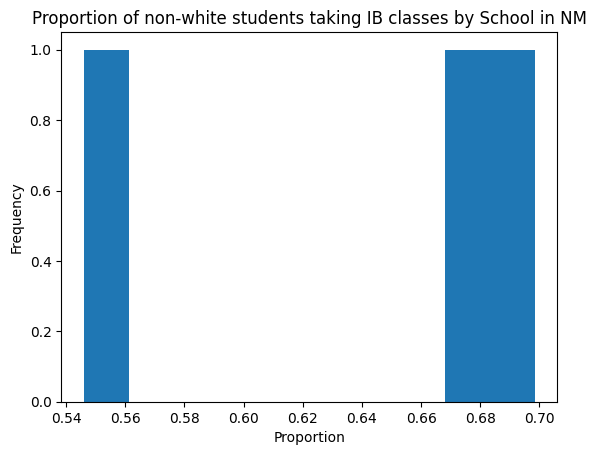

In [90]:
wh_nm = ib_nm['White Male'] + ib_nm['White Female']
total_nm = ib_nm['TotalF'] + ib_nm['TotalM']
non_white_nm = total_nm - wh_nm
nm_non_wh_prop = non_white_nm/total_nm
plt.hist(nm_non_wh_prop)
plt.xlabel('Proportion')
plt.ylabel('Frequency')
plt.title('Proportion of non-white students taking IB classes by School in NM')

**Alt-Text:** This is a  histogram showing the proportions of Non-white students per school in IB classes in New Mexico, with an X-axis of the proportion values, y-axis of frequency. It is bimodal.

Text(0.5, 1.0, 'Proportion of english-learner students taking IB classes by School in NM')

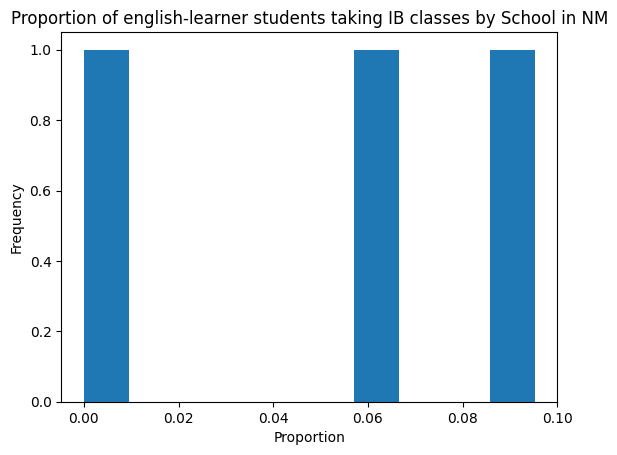

In [91]:
el_nm = ib_nm['EL Male'] + ib_nm['EL Female']
nm_el_prop = el_nm/total_nm
plt.hist(nm_el_prop)
plt.xlabel('Proportion')
plt.ylabel('Frequency')
plt.title('Proportion of english-learner students taking IB classes by School in NM')

**Alt-Test**: This is a  histogram showing the proportions of English learner students per school in IB classes in New Mexico, with an X-axis of the proportion values, y-axis of frequency. It is trimodal.

Text(0.5, 1.0, 'IDEA students taking IB classes by School in NM')

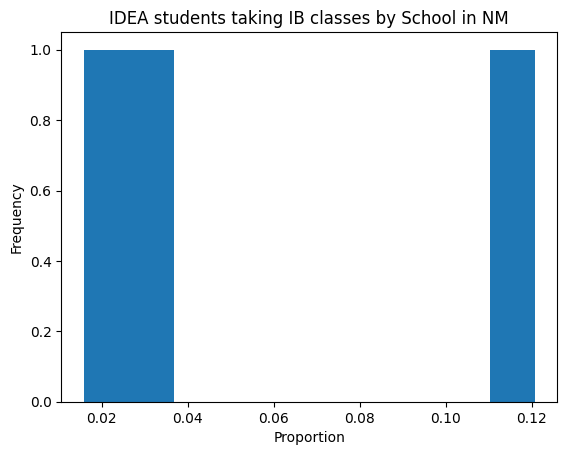

In [92]:
idea_nm = ib_nm['IDEA Male'] + ib_nm['IDEA Female']
nm_idea_prop = idea_nm/total_nm
plt.hist(nm_idea_prop)
plt.xlabel('Proportion')
plt.ylabel('Frequency')
plt.title('IDEA students taking IB classes by School in NM')

**Alt-Test**: This is a  histogram showing the proportions of IDEA students per school in IB classes in New Mexico, with an X-axis of the proportion values, y-axis of frequency. It is bimodal.



---



# 2. Texas

In [93]:
# clean dataframe to be TX schools
ib_tx = hs_has_ib.loc[(hs_has_ib['State']=='TX')]

# descriptive summary of statistics for Texas data
ib_tx.describe()

,Hispanic Male,Hispanic Female,Native American Male,Native American Female,Asian Male,Asian Female,Pacific Islander Male,Pacific Islander Female,Black Male,Black Female,...,EL Female,IDEA Male,IDEA Female,504_M,504_F,Total,Total White,Total Nonwhite,Total EL,Total IDEA
count,89.000000,89.000000,89.000000,89.000000,89.000000,89.000000,89.000000,89.000000,89.000000,89.000000,...,89.000000,89.000000,89.000000,89.000000,89.000000,89.000000,89.000000,89.000000,89.000000,89.000000
mean,30.865169,35.808989,0.134831,0.168539,9.000000,9.797753,0.078652,0.089888,5.393258,7.696629,...,8.539326,3.022472,1.449438,5.044944,5.988764,129.494382,26.584270,102.910112,18.449438,4.471910
std,40.658274,42.115338,0.375106,0.405529,19.060311,20.588048,0.270720,0.324753,15.265542,20.918350,...,13.674841,5.698839,2.545099,7.950000,8.002122,142.982447,40.517339,119.233312,30.100216,7.894316
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1.000000,0.000000,0.000000
25%,6.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,1.000000,1.000000,44.000000,3.000000,33.000000,1.000000,0.000000
50%,13.000000,20.000000,0.000000,0.000000,2.000000,1.000000,0.000000,0.000000,1.000000,2.000000,...,2.000000,0.000000,0.000000,2.000000,3.000000,120.000000,10.000000,70.000000,5.000000,1.000000
75%,41.000000,56.000000,0.000000,0.000000,6.000000,11.000000,0.000000,0.000000,4.000000,8.000000,...,9.000000,3.000000,2.000000,7.000000,9.000000,175.000000,36.000000,149.000000,15.000000,5.000000
max,224.000000,269.000000,2.000000,2.000000,133.000000,134.000000,1.000000,2.000000,132.000000,187.000000,...,66.000000,26.000000,15.000000,62.000000,50.000000,1216.000000,273.000000,943.000000,136.000000,41.000000


Text(0.5, 1.0, 'Proportion of non-white students taking IB classes by School in TX')

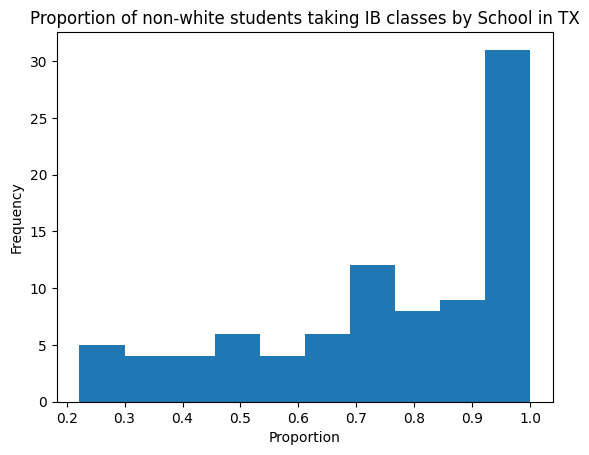

In [94]:
wh_tx = ib_tx['White Male'] + ib_tx['White Female']
total_tx = ib_tx['TotalF'] + ib_tx['TotalM']
non_white_tx = total_tx - wh_tx
tx_non_wh_prop = non_white_tx/total_tx
plt.hist(tx_non_wh_prop)
plt.xlabel('Proportion')
plt.ylabel('Frequency')
plt.title('Proportion of non-white students taking IB classes by School in TX')

This is a  histogram showing the proportions of Non-white students per school in IB classes in Texas, with an X-axis of the proportion values, y-axis of frequency. It is right skewed.

Text(0.5, 1.0, 'Proportion of english-learner students taking IB classes by School in TX')

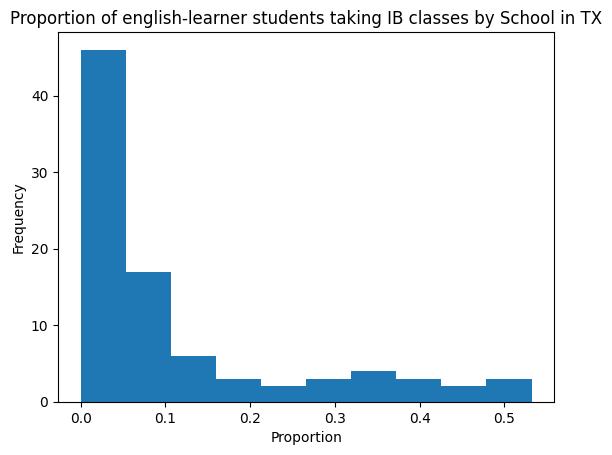

In [95]:
el_tx = ib_tx['EL Male'] + ib_tx['EL Female']
tx_el_prop = el_tx/total_tx
plt.hist(tx_el_prop)
plt.xlabel('Proportion')
plt.ylabel('Frequency')
plt.title('Proportion of english-learner students taking IB classes by School in TX')

**Alt-Test**: This is a  histogram showing the proportions of English learner students per school in IB classes in Texas, with an X-axis of the proportion values, y-axis of frequency. It is left skewed.

Text(0.5, 1.0, 'Proportion of IDEA students taking IB classes by School in TX')

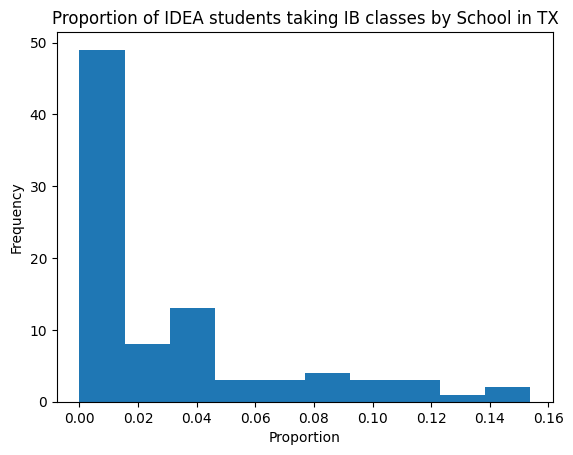

In [96]:
idea_tx = ib_tx['IDEA Male'] + ib_tx['IDEA Female']
tx_idea_prop = idea_tx/total_tx
plt.hist(tx_idea_prop)
plt.xlabel('Proportion')
plt.ylabel('Frequency')
plt.title('Proportion of IDEA students taking IB classes by School in TX')

**Alt-Test**: This is a  histogram showing the proportions of IDEA students per school in IB classes in Texas, with an X-axis of the proportion values, y-axis of frequency. It is right skewed.



---



# 4. Massachusetts

In [97]:
# clean dataframe to be MA schools
ib_ma = hs_has_ib.loc[(hs_has_ib['State']=='MA')]

# descriptive summary of statistics for Massachusetts data
ib_ma.describe()

,Hispanic Male,Hispanic Female,Native American Male,Native American Female,Asian Male,Asian Female,Pacific Islander Male,Pacific Islander Female,Black Male,Black Female,...,EL Female,IDEA Male,IDEA Female,504_M,504_F,Total,Total White,Total Nonwhite,Total EL,Total IDEA
count,13.000000,13.000000,13.0,13.0,13.000000,13.000000,13.000000,13.0,13.000000,13.000000,...,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000
mean,9.615385,11.538462,0.0,0.0,8.615385,6.615385,0.076923,0.0,10.153846,18.000000,...,2.384615,7.692308,6.461538,3.615385,3.846154,101.307692,32.769231,68.538462,6.461538,14.153846
std,17.085757,17.849442,0.0,0.0,18.857087,15.808956,0.277350,0.0,13.618897,23.643181,...,5.075077,11.607358,6.826607,4.682209,2.609155,78.487138,29.037774,81.247170,14.286447,18.054760
min,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,2.000000,0.000000,0.000000
25%,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.0,0.000000,1.000000,...,0.000000,1.000000,2.000000,0.000000,3.000000,36.000000,10.000000,12.000000,0.000000,2.000000
50%,3.000000,5.000000,0.0,0.0,1.000000,1.000000,0.000000,0.0,1.000000,6.000000,...,0.000000,2.000000,3.000000,2.000000,4.000000,92.000000,21.000000,17.000000,0.000000,4.000000
75%,9.000000,14.000000,0.0,0.0,5.000000,2.000000,0.000000,0.0,22.000000,28.000000,...,1.000000,9.000000,8.000000,4.000000,5.000000,158.000000,57.000000,120.000000,2.000000,18.000000
max,60.000000,63.000000,0.0,0.0,66.000000,57.000000,1.000000,0.0,37.000000,73.000000,...,16.000000,35.000000,22.000000,16.000000,9.000000,244.000000,84.000000,234.000000,41.000000,52.000000


Text(0.5, 1.0, 'Proportion of non-white students taking IB classes by School in MA')

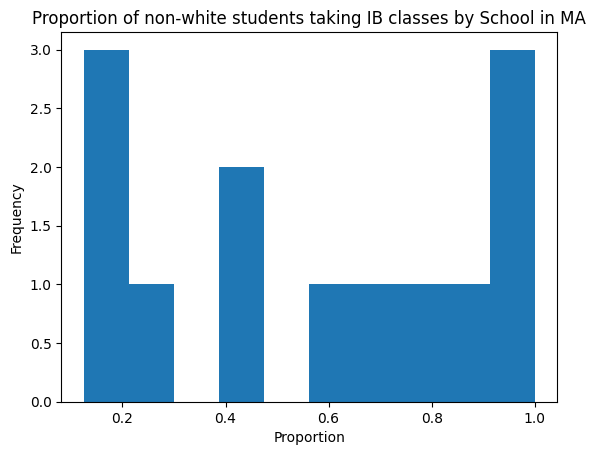

In [98]:
wh_ma = ib_ma['White Male'] + ib_ma['White Female']
total_ma = ib_ma['TotalF'] + ib_ma['TotalM']
non_white_ma = total_ma - wh_ma
ma_non_wh_prop = non_white_ma/total_ma
plt.hist(ma_non_wh_prop)
plt.xlabel('Proportion')
plt.ylabel('Frequency')
plt.title('Proportion of non-white students taking IB classes by School in MA')

**Alt-Test**: This is a  histogram showing the proportions of Non-white students per school in IB classes in Massachussets, with an X-axis of the proportion values, y-axis of frequency. It is bimodal.

Text(0.5, 1.0, 'Proportion of english-learner students taking IB classes by School in MA')

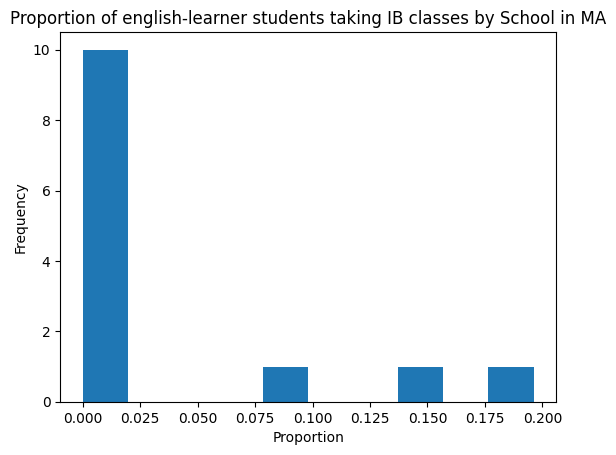

In [99]:
el_ma = ib_ma['EL Male'] + ib_ma['EL Female']
ma_el_prop = el_ma/total_ma
plt.hist(ma_el_prop)
plt.xlabel('Proportion')
plt.ylabel('Frequency')
plt.title('Proportion of english-learner students taking IB classes by School in MA')

**Alt-Test**: This is a  histogram showing the proportions of english-learner students per school in IB classes in Massachussets, with an X-axis of the proportion values, y-axis of frequency. It is left skewed.

Text(0.5, 1.0, 'Proportion of IDEA students taking IB classes by School in MA')

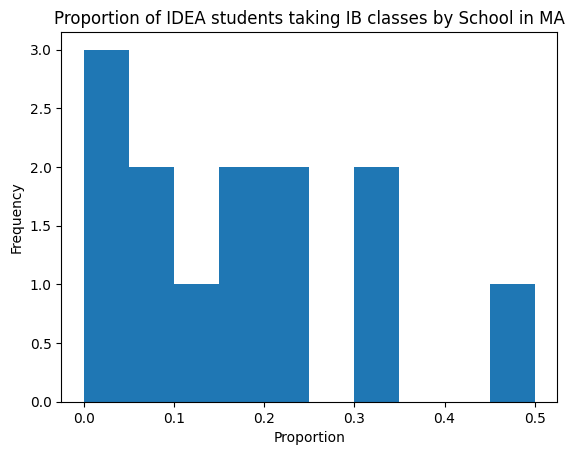

In [100]:
idea_ma = ib_ma['IDEA Male'] + ib_ma['IDEA Female']
ma_idea_prop = idea_ma/total_ma
plt.hist(ma_idea_prop)
plt.xlabel('Proportion')
plt.ylabel('Frequency')
plt.title('Proportion of IDEA students taking IB classes by School in MA')

**Alt-Test**: This is a  histogram showing the proportions of IDEA students per school in IB classes in Texas, with an X-axis of the proportion values, y-axis of frequency. It is left skewed.



---



In [101]:
ca_nm_tx_ma = [ib_ca, ib_nm, ib_tx, ib_ma]
ib_ca_nm_tx_ma = pd.concat(ca_nm_tx_ma)

In [102]:
ib_ca_nm_tx_ma.to_csv('IB Cleaned.csv', index = False)



---



### Cleaning the Data

A significant amound of cleaning had to be done to narrow down the data. This included taking out schools that didnt offer IB classes, and then cutting them to each state we are using. In addition, the names of the columns were changed to be understandable without having to cross-check them with a variable explination spreadsheet. The data was prepared by creating other variable to use for proportion calculation. These are specified in the EDA README.




---



### Exploring the Data

The outcome variables are the proportion of non white students, EL students, and IDEA studentsthat are in IB classes, and what this means in terms of equity in their representation in these classes. This relates to our expectations of a disproportionate number of white, able-bodies students having better educational opportunities. This is explained by the total numbers of students who are not white, EL, and IDEA, as well as the specific states we measured them in.
